# Stock Market Data Analysis and Basic Modeling

This notebook implements comprehensive analysis of Indian blue-chip stocks from the Nifty-50 index.

## Dataset Overview
- **Time Period**: January 2015 - October 2025
- **Stocks**: 14 blue-chip companies maintaining their position in Nifty-50
- **Data Source**: investing.com historical data

## Blue-Chip Companies Analyzed:
1. Reliance Industries Ltd
2. HDFC Bank Ltd  
3. ICICI Bank Ltd
4. Hindustan Unilever Ltd (HUL)
5. ITC Ltd
6. State Bank of India (SBI)
7. Bajaj Auto Ltd
8. Tata Motors Ltd
9. Tata Steel Ltd
10. Hindalco Industries Ltd
11. Larsen & Toubro Ltd (L&T)
12. Tata Consultancy Services (TCS)
13. Infosys Ltd
14. Nifty-50 Index

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Set plotting style
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

print("Libraries imported successfully!")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")

Libraries imported successfully!
Pandas version: 2.3.3
NumPy version: 2.3.3


In [2]:
# Define file paths and stock names
import os
data_path = r"e:\Modelling\Project\Data -Working"

# Stock file mapping
stock_files = {
    'BAJAJ': 'BAJAJ-Historical-Data.csv',
    'HDFC_BANK': 'HDFCBank-Historical-Data.csv',
    'HINDALCO': 'Hindalco-Historical-Data.csv',
    'HUL': 'HUL-Historical-Data.csv',
    'ICICI_BANK': 'ICICIBank-Historical-Data.csv',
    'INFOSYS': 'Infosys-Historical- Data.csv',
    'ITC': 'ITC-Historical-Data.csv',
    'LT': 'L&T-Historical-Data.csv',
    'NIFTY50': 'Nifty-50-Historical-Data.csv',
    'RELIANCE': 'RelianceIndustries-Historical-Data.csv',
    'SBI': 'SBI-Historical-Data.csv',
    'TATA_MOTORS': 'TATAMotors-Historical-Data.csv',
    'TATA_STEEL': 'TataSteel-Historical-Data.csv',
    'TCS': 'TCS-Historical-Data.csv'
}

print(f"Data directory: {data_path}")
print(f"Number of stock files: {len(stock_files)}")
print("Stock symbols:", list(stock_files.keys()))

Data directory: e:\Modelling\Project\Data -Working
Number of stock files: 14
Stock symbols: ['BAJAJ', 'HDFC_BANK', 'HINDALCO', 'HUL', 'ICICI_BANK', 'INFOSYS', 'ITC', 'LT', 'NIFTY50', 'RELIANCE', 'SBI', 'TATA_MOTORS', 'TATA_STEEL', 'TCS']


In [3]:
def load_stock_data(file_path):
    """
    Load and preprocess individual stock data
    """
    try:
        # Read CSV file
        df = pd.read_csv(file_path)
        
        # Clean column names (remove quotes if present)
        df.columns = df.columns.str.replace('"', '')
        
        # Convert Date column to datetime
        df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')
        
        # Clean numeric columns (remove commas and convert to float)
        numeric_columns = ['Price', 'Open', 'High', 'Low']
        for col in numeric_columns:
            if col in df.columns:
                df[col] = df[col].astype(str).str.replace(',', '').astype(float)
        
        # Handle Volume column
        if 'Vol.' in df.columns:
            df['Volume'] = df['Vol.'].astype(str).str.replace(',', '')
            # Convert volume (handle M, K suffixes)
            df['Volume'] = df['Volume'].apply(convert_volume)
            df = df.drop('Vol.', axis=1)
        
        # Handle Change % column
        if 'Change %' in df.columns:
            df['Change_Pct'] = df['Change %'].astype(str).str.replace('%', '').astype(float)
            df = df.drop('Change %', axis=1)
        
        # Sort by date (oldest first)
        df = df.sort_values('Date').reset_index(drop=True)
        
        return df
    
    except Exception as e:
        print(f"Error loading {file_path}: {str(e)}")
        return None

def convert_volume(vol_str):
    """
    Convert volume string to numeric (handle M, K suffixes)
    """
    try:
        vol_str = str(vol_str).strip()
        if vol_str.endswith('M'):
            return float(vol_str[:-1]) * 1_000_000
        elif vol_str.endswith('K'):
            return float(vol_str[:-1]) * 1_000
        else:
            return float(vol_str)
    except:
        return np.nan

print("Data loading functions defined successfully!")

Data loading functions defined successfully!


In [4]:
# Load all stock data
stock_data = {}
failed_loads = []

print("Loading stock data...")
for symbol, filename in stock_files.items():
    file_path = os.path.join(data_path, filename)
    print(f"Loading {symbol}...")
    
    data = load_stock_data(file_path)
    if data is not None:
        stock_data[symbol] = data
        print(f"  ✓ {symbol}: {len(data)} records loaded")
    else:
        failed_loads.append(symbol)
        print(f"  ✗ {symbol}: Failed to load")

print(f"\nSummary:")
print(f"Successfully loaded: {len(stock_data)} files")
print(f"Failed to load: {len(failed_loads)} files")
if failed_loads:
    print(f"Failed files: {failed_loads}")

Loading stock data...
Loading BAJAJ...
  ✓ BAJAJ: 2665 records loaded
Loading HDFC_BANK...
  ✓ HDFC_BANK: 2666 records loaded
Loading HINDALCO...
  ✓ HINDALCO: 2665 records loaded
Loading HUL...
  ✓ HUL: 2665 records loaded
Loading ICICI_BANK...
  ✓ ICICI_BANK: 2665 records loaded
Loading INFOSYS...
  ✓ INFOSYS: 2665 records loaded
Loading ITC...
  ✓ ITC: 2666 records loaded
Loading LT...
  ✓ LT: 2665 records loaded
Loading NIFTY50...
  ✓ NIFTY50: 2666 records loaded
Loading RELIANCE...
  ✓ RELIANCE: 2666 records loaded
Loading SBI...
  ✓ SBI: 2666 records loaded
Loading TATA_MOTORS...
  ✓ TATA_MOTORS: 2665 records loaded
Loading TATA_STEEL...
  ✓ TATA_STEEL: 2666 records loaded
Loading TCS...
  ✓ TCS: 2665 records loaded

Summary:
Successfully loaded: 14 files
Failed to load: 0 files


In [5]:
# Explore data structure
print("=== DATA STRUCTURE ANALYSIS ===\n")

# Sample data from TCS
sample_stock = 'TCS'
print(f"Sample data structure ({sample_stock}):")
print(stock_data[sample_stock].head())
print(f"\nColumns: {list(stock_data[sample_stock].columns)}")
print(f"Data types:\n{stock_data[sample_stock].dtypes}")
print(f"Shape: {stock_data[sample_stock].shape}")

# Date range analysis
print(f"\n=== DATE RANGE ANALYSIS ===")
for symbol in list(stock_data.keys())[:5]:  # Show first 5 stocks
    df = stock_data[symbol]
    print(f"{symbol}: {df['Date'].min()} to {df['Date'].max()} ({len(df)} records)")

# Check for missing values
print(f"\n=== MISSING VALUES ANALYSIS ===")
for symbol in ['TCS', 'RELIANCE', 'NIFTY50']:  # Check key stocks
    df = stock_data[symbol]
    missing = df.isnull().sum()
    if missing.any():
        print(f"{symbol}:\n{missing[missing > 0]}")
    else:
        print(f"{symbol}: No missing values")

=== DATA STRUCTURE ANALYSIS ===

Sample data structure (TCS):
        Date    Price     Open     High      Low     Volume  Change_Pct
0 2015-01-01  1247.90  1258.41  1258.41  1245.67   366830.0       -0.50
1 2015-01-02  1264.51  1250.57  1270.15  1250.37   925740.0        1.33
2 2015-01-05  1245.30  1265.27  1274.54  1237.65  1750000.0       -1.52
3 2015-01-06  1199.39  1239.83  1239.83  1196.15  2420000.0       -3.69
4 2015-01-07  1185.22  1210.86  1215.35  1180.20  2640000.0       -1.18

Columns: ['Date', 'Price', 'Open', 'High', 'Low', 'Volume', 'Change_Pct']
Data types:
Date          datetime64[ns]
Price                float64
Open                 float64
High                 float64
Low                  float64
Volume               float64
Change_Pct           float64
dtype: object
Shape: (2665, 7)

=== DATE RANGE ANALYSIS ===
BAJAJ: 2015-01-01 00:00:00 to 2025-10-03 00:00:00 (2665 records)
HDFC_BANK: 2015-01-01 00:00:00 to 2025-10-03 00:00:00 (2666 records)
HINDALCO: 2015-01-01 0

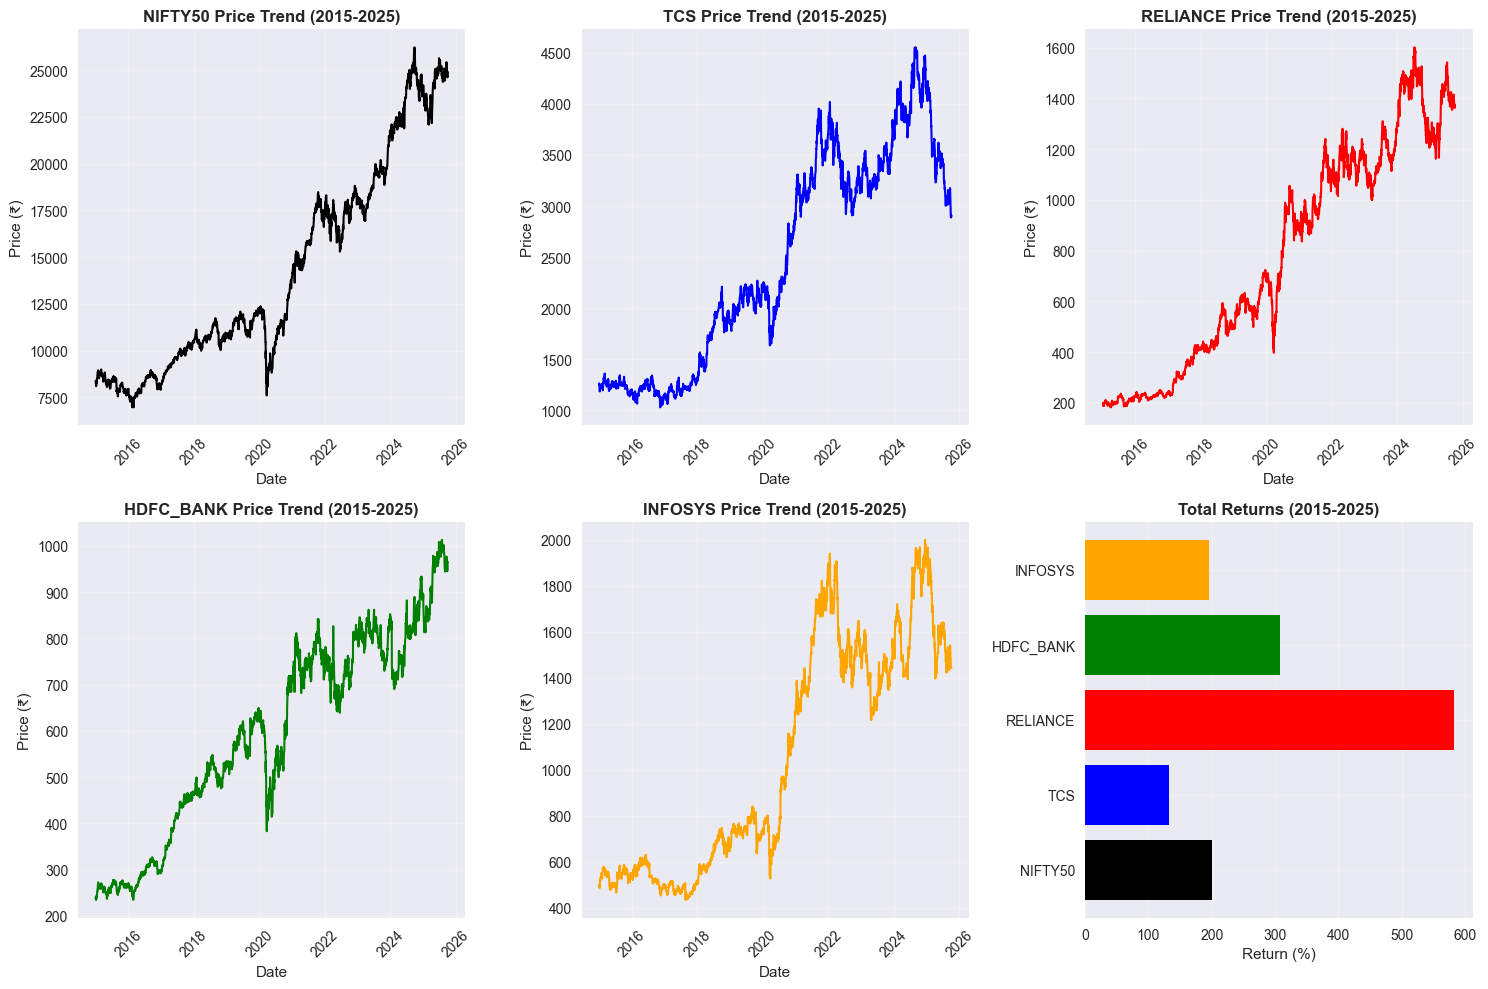

Price trend analysis completed!


In [6]:
# Create price trend visualization
plt.figure(figsize=(15, 10))

# Plot key stocks
key_stocks = ['NIFTY50', 'TCS', 'RELIANCE', 'HDFC_BANK', 'INFOSYS']
colors = ['black', 'blue', 'red', 'green', 'orange']

for i, stock in enumerate(key_stocks):
    df = stock_data[stock]
    plt.subplot(2, 3, i+1)
    plt.plot(df['Date'], df['Price'], color=colors[i], linewidth=1.5)
    plt.title(f'{stock} Price Trend (2015-2025)', fontsize=12, fontweight='bold')
    plt.xlabel('Date')
    plt.ylabel('Price (₹)')
    plt.xticks(rotation=45)
    plt.grid(True, alpha=0.3)

# Summary statistics subplot
plt.subplot(2, 3, 6)
summary_data = []
for stock in key_stocks:
    df = stock_data[stock]
    summary_data.append([
        stock,
        df['Price'].iloc[0],  # Starting price
        df['Price'].iloc[-1], # Current price
        ((df['Price'].iloc[-1] / df['Price'].iloc[0]) - 1) * 100  # Total return %
    ])

summary_df = pd.DataFrame(summary_data, columns=['Stock', 'Start_Price', 'Current_Price', 'Total_Return_%'])
plt.barh(summary_df['Stock'], summary_df['Total_Return_%'], color=colors)
plt.title('Total Returns (2015-2025)', fontweight='bold')
plt.xlabel('Return (%)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Price trend analysis completed!")

## Feature Engineering

Now we'll create technical indicators and additional features for modeling:

In [7]:
def add_technical_indicators(df):
    """
    Add technical indicators to the dataframe
    """
    df = df.copy()
    
    # Simple Moving Averages
    df['SMA_20'] = df['Price'].rolling(window=20).mean()
    df['SMA_50'] = df['Price'].rolling(window=50).mean()
    df['SMA_200'] = df['Price'].rolling(window=200).mean()
    
    # Exponential Moving Averages
    df['EMA_12'] = df['Price'].ewm(span=12).mean()
    df['EMA_26'] = df['Price'].ewm(span=26).mean()
    
    # MACD
    df['MACD'] = df['EMA_12'] - df['EMA_26']
    df['MACD_Signal'] = df['MACD'].ewm(span=9).mean()
    df['MACD_Histogram'] = df['MACD'] - df['MACD_Signal']
    
    # RSI (Relative Strength Index)
    delta = df['Price'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
    rs = gain / loss
    df['RSI'] = 100 - (100 / (1 + rs))
    
    # Bollinger Bands
    df['BB_Middle'] = df['SMA_20']
    bb_std = df['Price'].rolling(window=20).std()
    df['BB_Upper'] = df['BB_Middle'] + (bb_std * 2)
    df['BB_Lower'] = df['BB_Middle'] - (bb_std * 2)
    df['BB_Width'] = df['BB_Upper'] - df['BB_Lower']
    df['BB_Position'] = (df['Price'] - df['BB_Lower']) / (df['BB_Upper'] - df['BB_Lower'])
    
    # Price-based features
    df['Daily_Return'] = df['Price'].pct_change()
    df['Log_Return'] = np.log(df['Price'] / df['Price'].shift(1))
    df['Volatility_20'] = df['Daily_Return'].rolling(window=20).std()
    df['Price_Range'] = df['High'] - df['Low']
    df['Price_Position'] = (df['Price'] - df['Low']) / (df['High'] - df['Low'])
    
    # Volume-based features
    if 'Volume' in df.columns:
        df['Volume_SMA_20'] = df['Volume'].rolling(window=20).mean()
        df['Volume_Ratio'] = df['Volume'] / df['Volume_SMA_20']
        df['Price_Volume'] = df['Price'] * df['Volume']
    
    # Momentum indicators
    df['Price_Momentum_5'] = df['Price'] / df['Price'].shift(5) - 1
    df['Price_Momentum_10'] = df['Price'] / df['Price'].shift(10) - 1
    df['Price_Momentum_20'] = df['Price'] / df['Price'].shift(20) - 1
    
    # Support and Resistance levels
    df['High_20'] = df['High'].rolling(window=20).max()
    df['Low_20'] = df['Low'].rolling(window=20).min()
    
    return df

print("Technical indicators function created!")

Technical indicators function created!


In [8]:
# Apply technical indicators to all stocks
print("Adding technical indicators to all stocks...")
enhanced_stock_data = {}

for symbol, df in stock_data.items():
    print(f"Processing {symbol}...")
    enhanced_df = add_technical_indicators(df)
    enhanced_stock_data[symbol] = enhanced_df
    print(f"  Added {len(enhanced_df.columns) - len(df.columns)} new features")

print(f"\nEnhanced data structure:")
sample_stock = 'TCS'
print(f"Original columns: {len(stock_data[sample_stock].columns)}")
print(f"Enhanced columns: {len(enhanced_stock_data[sample_stock].columns)}")
print(f"New columns added: {len(enhanced_stock_data[sample_stock].columns) - len(stock_data[sample_stock].columns)}")

print(f"\nNew feature columns:")
original_cols = set(stock_data[sample_stock].columns)
new_cols = set(enhanced_stock_data[sample_stock].columns) - original_cols
print(list(new_cols))

Adding technical indicators to all stocks...
Processing BAJAJ...
  Added 27 new features
Processing HDFC_BANK...
  Added 27 new features
Processing HINDALCO...
  Added 27 new features
Processing HUL...
  Added 27 new features
Processing ICICI_BANK...
  Added 27 new features
Processing INFOSYS...
  Added 27 new features
Processing ITC...
  Added 27 new features
Processing LT...
  Added 27 new features
Processing NIFTY50...
  Added 27 new features
Processing RELIANCE...
  Added 27 new features
Processing SBI...
  Added 27 new features
Processing TATA_MOTORS...
  Added 27 new features
Processing TATA_STEEL...
  Added 27 new features
Processing TCS...
  Added 27 new features

Enhanced data structure:
Original columns: 7
Enhanced columns: 34
New columns added: 27

New feature columns:
['EMA_12', 'BB_Middle', 'SMA_50', 'Price_Volume', 'RSI', 'Price_Range', 'BB_Upper', 'MACD_Histogram', 'BB_Width', 'MACD_Signal', 'Volume_SMA_20', 'Log_Return', 'SMA_200', 'Low_20', 'BB_Lower', 'Price_Momentum_

Creating correlation analysis...


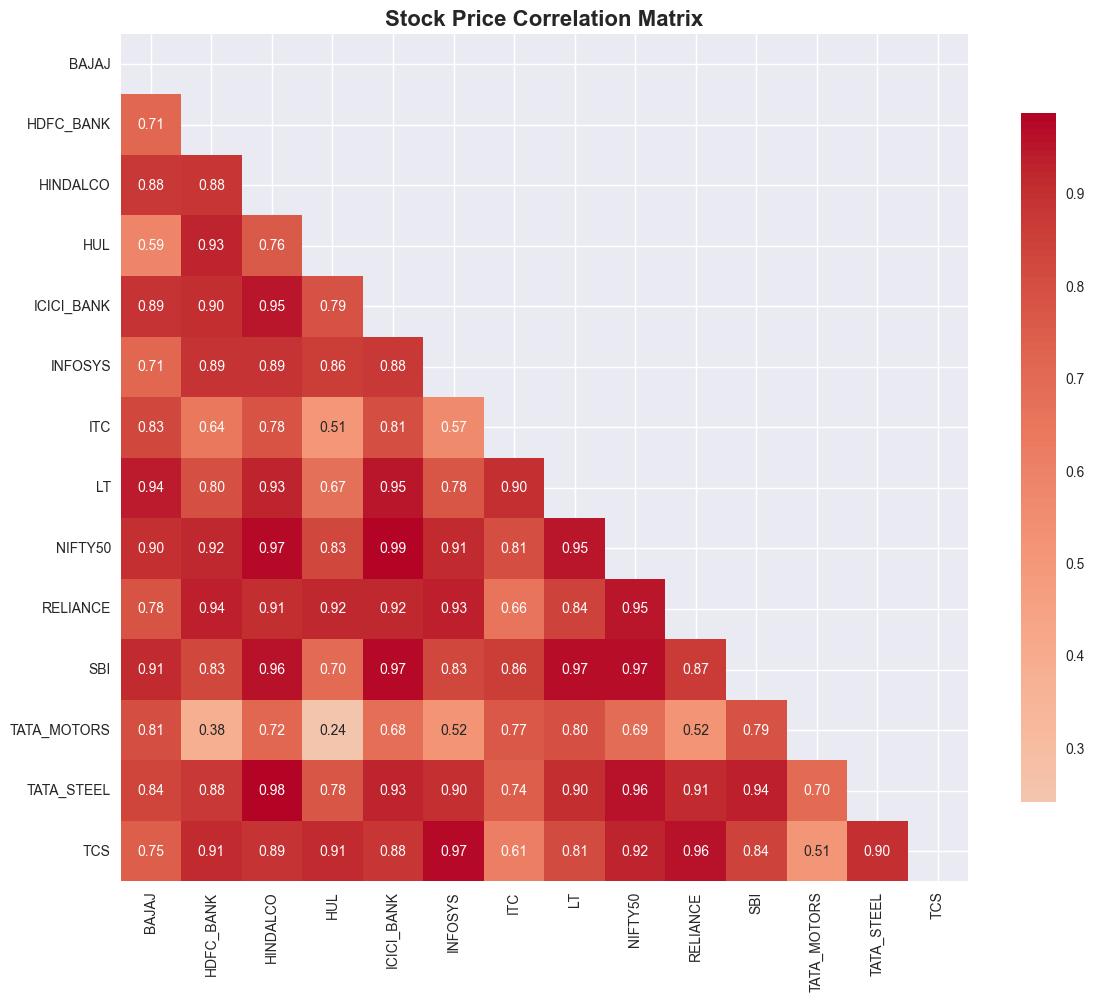


Highly correlated stock pairs (>0.8):
ICICI_BANK - NIFTY50: 0.987
HINDALCO - TATA_STEEL: 0.982
INFOSYS - TCS: 0.975
HINDALCO - NIFTY50: 0.974
ICICI_BANK - SBI: 0.971
NIFTY50 - SBI: 0.968
LT - SBI: 0.967
RELIANCE - TCS: 0.961
NIFTY50 - TATA_STEEL: 0.960
HINDALCO - SBI: 0.956
HINDALCO - ICICI_BANK: 0.951
LT - NIFTY50: 0.951
NIFTY50 - RELIANCE: 0.950
ICICI_BANK - LT: 0.947
BAJAJ - LT: 0.941
HDFC_BANK - RELIANCE: 0.938
SBI - TATA_STEEL: 0.936
INFOSYS - RELIANCE: 0.932
HDFC_BANK - HUL: 0.931
ICICI_BANK - TATA_STEEL: 0.929
HINDALCO - LT: 0.926
NIFTY50 - TCS: 0.925
ICICI_BANK - RELIANCE: 0.922
HDFC_BANK - NIFTY50: 0.921
HUL - RELIANCE: 0.921
HDFC_BANK - TCS: 0.914
BAJAJ - SBI: 0.911
INFOSYS - NIFTY50: 0.911
RELIANCE - TATA_STEEL: 0.910
HUL - TCS: 0.909
HINDALCO - RELIANCE: 0.906
HDFC_BANK - ICICI_BANK: 0.900
LT - TATA_STEEL: 0.900
INFOSYS - TATA_STEEL: 0.898
TATA_STEEL - TCS: 0.898
ITC - LT: 0.896
BAJAJ - NIFTY50: 0.896
HINDALCO - INFOSYS: 0.890
BAJAJ - ICICI_BANK: 0.887
HINDALCO - TCS: 0.88

In [9]:
# Create correlation matrix for key stocks
print("Creating correlation analysis...")

# Get price data for correlation
price_data = {}
for symbol, df in enhanced_stock_data.items():
    price_data[symbol] = df.set_index('Date')['Price']

# Combine into single dataframe
price_df = pd.DataFrame(price_data)

# Calculate correlation matrix
correlation_matrix = price_df.corr()

# Visualize correlation matrix
plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(correlation_matrix, 
            mask=mask,
            annot=True, 
            cmap='coolwarm', 
            center=0,
            square=True,
            fmt='.2f',
            cbar_kws={"shrink": .8})
plt.title('Stock Price Correlation Matrix', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Identify highly correlated pairs
high_corr_pairs = []
for i in range(len(correlation_matrix.columns)):
    for j in range(i+1, len(correlation_matrix.columns)):
        corr_value = correlation_matrix.iloc[i, j]
        if abs(corr_value) > 0.8:  # High correlation threshold
            high_corr_pairs.append((correlation_matrix.columns[i], 
                                  correlation_matrix.columns[j], 
                                  corr_value))

print(f"\nHighly correlated stock pairs (>0.8):")
for stock1, stock2, corr in sorted(high_corr_pairs, key=lambda x: abs(x[2]), reverse=True):
    print(f"{stock1} - {stock2}: {corr:.3f}")